Seçtiğim Alan= Sağlık ve Sigortacılık
Bireyin yaşı, vücut kitle indeksi (BMI), bakmakla yükümlü olduğu çocuk sayısı, cinsiyeti, yaşadığı bölge ve sigara kullanım durumu bilgilerinden yıllık sağlık sigortası masrafını tahmin eden model oluşturcağım.

Özellikler (x): Yaş (age), Cinsiyet (sex), Vücut Kitle İndeksi (bmi), Çocuk Sayısı (children), Sigara Kullanımı (smoker), Bölge (region).

Hedef Değişken (y): Yıllık Sağlık Masrafı (charges - Dolar cinsinden sürekli sayısal değer)

Problem Türü: Regresyon

Proje Gerekçesi= Sağlık harcamalarının bireysel yaşam tarzı ve demografik faktörlere bağlı olarak nasıl değiştiğini öngörebilmek, hem sağlık sigortası şirketleri hem de bireyler için kritik bir finansal planlama aracıdır. Sigorta kurumları, poliçe fiyatlandırmalarını rastgele tahminler yerine kişilerin yaş, vücut kitle indeksi ve sigara kullanımı gibi somut risk faktörlerine dayandırarak daha adil ve sürdürülebilir prim politikaları belirleyebilir. Bireyler açısından ise bu model, özellikle sigara kullanımı ve kilo kontrolü gibi değiştirilebilir yaşam tarzı alışkanlıklarının yıllık sağlık maliyetleri üzerindeki doğrudan finansal etkisini somut rakamlarla görerek önleyici sağlık adımları atmalarına ve bütçe planlaması yapmalarına katkı sağlar.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report


In [ ]:
# Veri setini internetten çekip Colab çalışma dizinine 'saglik_sigortasi.csv' adıyla kaydediyoruz
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
ham_veri = pd.read_csv(url)
ham_veri.to_csv("saglik_sigortasi.csv", index=False)

# Kaydettiğimiz CSV dosyasını Pandas ile okuyoruz
df = pd.read_csv("saglik_sigortasi.csv")

In [ ]:
# İlk 10 satırı ve toplam satır/sütun sayısını görelim
print(f"Veri seti boyutu: {df.shape[0]} satır, {df.shape[1]} sütun")
df.head(10)

Veri seti boyutu: 1338 satır, 7 sütun


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


Özellikler (x): Yaş (age), Cinsiyet (sex), Vücut Kitle İndeksi (bmi), Çocuk Sayısı (children), Sigara Kullanımı (smoker), Bölge (region).

Hedef Değişken (y): Yıllık Sağlık Masrafı (charges - Dolar cinsinden sürekli sayısal değer)

In [ ]:
# Tüm sütunların veri tiplerini tek tek görelim
print("--- SÜTUN VERİ TİPLERİ (dtypes) ---")
print(df.dtypes)

--- SÜTUN VERİ TİPLERİ (dtypes) ---
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [ ]:
#  Eksik (Null / NaN) değer kontrolü
print("\n---  EKSİK (NULL) DEĞER SAYISI ---")
print(df.isnull().sum())

#  Sayısal sütunlarda 0 veya negatif (hatalı) değer var mı kontrol edelim
print("\n--- SIFIR VEYA NEGATİF DEĞER KONTROLÜ ---")
sayisal_sutunlar = ["age", "bmi", "children", "charges"]
for sutun in sayisal_sutunlar:
    sifir_sayisi = (df[sutun] == 0).sum()
    negatif_sayisi = (df[sutun] < 0).sum()
    print(f"{sutun} -> 0 değeri sayısı: {sifir_sayisi} | Negatif değer sayısı: {negatif_sayisi}")

#  Kategorik sütunlarda yazım hatası veya beklenmeyen kategori var mı?
print("\n---  KATEGORİK SÜTUN DEĞERLERİ ---")
for sutun in ["sex", "smoker", "region"]:
    print(f"{sutun}: {df[sutun].unique()}")

# Tekrar eden (Duplicate) satır var mı kontrol edelim
print(f"\n---  TEKRAR EDEN (DUPLICATE) SATIR SAYISI: {df.duplicated().sum()} ---")


---  EKSİK (NULL) DEĞER SAYISI ---
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

--- SIFIR VEYA NEGATİF DEĞER KONTROLÜ ---
age -> 0 değeri sayısı: 0 | Negatif değer sayısı: 0
bmi -> 0 değeri sayısı: 0 | Negatif değer sayısı: 0
children -> 0 değeri sayısı: 574 | Negatif değer sayısı: 0
charges -> 0 değeri sayısı: 0 | Negatif değer sayısı: 0

---  KATEGORİK SÜTUN DEĞERLERİ ---
sex: ['female' 'male']
smoker: ['yes' 'no']
region: ['southwest' 'southeast' 'northwest' 'northeast']

---  TEKRAR EDEN (DUPLICATE) SATIR SAYISI: 1 ---


In [ ]:
# Tekrar eden satırı görelim
print("Tekrar eden satır:")
print(df[df.duplicated(keep=False)])

# Tekrar eden satırı veri setinden çıkaralım
df = df.drop_duplicates().reset_index(drop=True)

# Temizlik sonrası güncel boyutu doğrulayalım
print(f"\nTemizlik sonrası yeni veri seti boyutu: {df.shape[0]} satır, {df.shape[1]} sütun")

Tekrar eden satır:
     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631

Temizlik sonrası yeni veri seti boyutu: 1337 satır, 7 sütun


In [ ]:
# Sayısal değişkenlerin özet istatistikleri (Ortalama, std, min, max, çeyreklikler)
print("---  SAYISAL ÖZET İSTATİSTİKLER (describe) ---")
display(df.describe().round(2))

---  SAYISAL ÖZET İSTATİSTİKLER (describe) ---


,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


In [ ]:
# Sayısal değişkenlerin özet istatistikleri (Ortalama, std, min, max, çeyreklikler)
print("--- SAYISAL DEĞİŞKENLER ÖZET İSTATİSTİKLERİ (describe) ---")
display(df.describe().round(2))

--- SAYISAL DEĞİŞKENLER ÖZET İSTATİSTİKLERİ (describe) ---


,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


In [ ]:
# Kategorik değişkenlerin (metin sütunlarının) özet istatistikleri
print("\n--- KATEGORİK DEĞİŞKENLER ÖZETİ (describe include='object') ---")
display(df.describe(include="object"))


--- KATEGORİK DEĞİŞKENLER ÖZETİ (describe include='object') ---


,sex,smoker,region
count,1337,1337,1337
unique,2,2,4
top,male,no,southeast
freq,675,1063,364


In [ ]:
# Kategorik değişkenlerin dağılımı (value_counts)
print("\n---  SİGARA KULLANIMI VE CİNSİYET DAĞILIMI (value_counts) ---")
print("Sigara Kullanımı:")
print(df["smoker"].value_counts())
print("\nBölgelere Göre Dağılım:")
print(df["region"].value_counts())


---  SİGARA KULLANIMI VE CİNSİYET DAĞILIMI (value_counts) ---
Sigara Kullanımı:
smoker
no     1063
yes     274
Name: count, dtype: int64

Bölgelere Göre Dağılım:
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


In [ ]:
#  Cinsiyete Göre Detaylı İstatistikler (Sayı, Ortalama, Medyan, Min, Max)
print("---  CİNSİYETE GÖRE SAĞLIK MASRAFI ANALİZİ ---")
print(df.groupby("sex")["charges"].agg(["count", "mean", "median", "min", "max"]).round(2))

---  CİNSİYETE GÖRE SAĞLIK MASRAFI ANALİZİ ---
        count      mean   median      min       max
sex                                                
female    662  12569.58  9412.96  1607.51  63770.43
male      675  13975.00  9377.90  1121.87  62592.87


In [ ]:
#  Çocuk Sayısına Göre Ortalama Sağlık Masrafı
print("\n---  ÇOCUK SAYISINA GÖRE ORTALAMA SAĞLIK MASRAFI ---")
print(df.groupby("children")["charges"].agg(["count", "mean", "median"]).round(2))


---  ÇOCUK SAYISINA GÖRE ORTALAMA SAĞLIK MASRAFI ---
          count      mean    median
children                           
0           573  12384.70   9863.47
1           324  12731.17   8483.87
2           240  15073.56   9264.98
3           157  15355.32  10600.55
4            25  13850.66  11033.66
5            18   8786.04   8589.57


In [ ]:
#  Vücut Kitle İndeksi (BMI) Kategorilerine Göre Analiz
# Tıbbi standartlara göre geçici bir kategori sütunu oluşturalım
bmi_siniflari = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 24.9, 29.9, 100],
    labels=["Zayıf (<18.5)", "Normal (18.5-24.9)", "Fazla Kilolu (25-29.9)", "Obez (30+)"]
)
print("\n---  VÜCUT KİTLE İNDEKSİ (BMI) GRUPLARINA GÖRE MASRAF ---")
print(df.groupby(bmi_siniflari, observed=False)["charges"].agg(["count", "mean", "median"]).round(2))


---  VÜCUT KİTLE İNDEKSİ (BMI) GRUPLARINA GÖRE MASRAF ---
                        count      mean   median
bmi                                             
Zayıf (<18.5)              21   8657.62  6640.54
Normal (18.5-24.9)        221  10404.90  8604.48
Fazla Kilolu (25-29.9)    380  11006.81  8659.38
Obez (30+)                715  15510.92  9910.36


In [ ]:
#  Yaş Gruplarına Göre Ortalama Sağlık Masrafı
yas_gruplari = pd.cut(
    df["age"],
    bins=[17, 29, 44, 65],
    labels=["Genç Yetişkin (18-29)", "Orta Yaş (30-44)", "İleri Yaş (45-64)"]
)
print("\n---  YAŞ GRUPLARINA GÖRE ORTALAMA SAĞLIK MASRAFI ---")
print(df.groupby(yas_gruplari, observed=False)["charges"].agg(["count", "mean", "median"]).round(2))


---  YAŞ GRUPLARINA GÖRE ORTALAMA SAĞLIK MASRAFI ---
                       count      mean    median
age                                             
Genç Yetişkin (18-29)    416   9200.62   3220.37
Orta Yaş (30-44)         392  12490.91   6798.16
İleri Yaş (45-64)        529  17070.49  12029.29


Yaş ilerledikçe (18-29'dan 45-64'e geçtikçe) ortalama masraf artıyor.

In [ ]:
#  Çapraz Analiz: BMI Kategorisi + Sigara Kullanımı Birlikte Nasıl Etkiliyor?
print("\n---  BMI GRUBU VE SİGARA KULLANIMI ÇAPRAZ ANALİZİ (ORTALAMA MASRAF) ---")
print(df.groupby([bmi_siniflari, "smoker"], observed=False)["charges"].mean().unstack().round(2))


---  BMI GRUBU VE SİGARA KULLANIMI ÇAPRAZ ANALİZİ (ORTALAMA MASRAF) ---
smoker                       no       yes
bmi                                      
Zayıf (<18.5)           5485.06  18809.82
Normal (18.5-24.9)      7616.21  19942.22
Fazla Kilolu (25-29.9)  8348.37  22379.03
Obez (30+)              8822.17  41355.87


In [ ]:
#  Çapraz analiz tablosunu oluşturalım
capraz_analiz = df.groupby([bmi_siniflari, "smoker"], observed=False)["charges"].mean().unstack().round(2)

# Sütun isimlerini grafikte daha anlaşılır görünmesi için Türkçeleştirelim
capraz_analiz = capraz_analiz.rename(columns={"no": "Sigara İçmiyor", "yes": "Sigara İçiyor"})

#  Grafik boyutunu ve stilini ayarlayalım
plt.figure(figsize=(10, 6))
ax = capraz_analiz.plot(
    kind="bar",
    color=["#38bdf8", "#f43f5e"],  # Camgöbeği (Sigarasız) ve Mercan Kırmızısı (Sigaralı)
    edgecolor="none",
    width=0.72,
    ax=plt.gca()
)

#  Başlık ve eksen etiketlerini düzenleyelim
plt.title("BMI Kategorisi ve Sigara Kullanımına Göre Ortalama Yıllık Sağlık Masrafı", fontsize=14, fontweight="bold", pad=16)
plt.xlabel("BMI (Vücut Kitle İndeksi) Kategorisi", fontsize=11, fontweight="bold", labelpad=10)
plt.ylabel("Ortalama Yıllık Masraf ($)", fontsize=11, fontweight="bold", labelpad=10)
plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)
plt.ylim(0, capraz_analiz.values.max() * 1.15)  # Üstteki rakamların kesilmemesi için boşluk

#  Her sütunun üzerine kesin Dolar tutarını yazdıralım
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=4,
        fontsize=9.5,
        fontweight="bold"
    )

#  Izgara ve açıklama kutusunu (legend) ekleyelim
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(title="Sigara Durumu", fontsize=10, title_fontsize=10.5, frameon=True)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

In [ ]:
#  Sayısal Değişkenlerin Hedef Değişken (charges) ile Korelasyonu
print("\n--- SAYISAL DEĞİŞKENLERİN MASRAF İLE KORELASYONU ---")
print(df[["age", "bmi", "children", "charges"]].corr()["charges"].sort_values(ascending=False).round(3))


--- SAYISAL DEĞİŞKENLERİN MASRAF İLE KORELASYONU ---
charges     1.000
age         0.298
bmi         0.198
children    0.067
Name: charges, dtype: float64


Sigara içmeyen obez bir birey ile sigara içen obez bir birey arasında 5 kat yıllık sağlık masrafı farkı oluşuyor.Yüksek BMI tek başına masrafı bu kadar artırmazken, sigara kullanımı ile birleştiğinde sağlık maliyetlerinde katlanarak artan  bir risk yaratıyor.

In [ ]:
# Hedef değişkene (charges) göre gruplama analizleri (groupby)
print("\n--- SİGARA KULLANIMINA GÖRE ORTALAMA SAĞLIK MASRAFI (groupby) ---")
print(df.groupby("smoker")["charges"].agg(["count", "mean", "median", "min", "max"]).round(2))


--- SİGARA KULLANIMINA GÖRE ORTALAMA SAĞLIK MASRAFI (groupby) ---
        count      mean    median       min       max
smoker                                               
no       1063   8440.66   7345.73   1121.87  36910.61
yes       274  32050.23  34456.35  12829.46  63770.43


Sigara içenlerin ortalama yıllık sağlık masrafları içmeyenlere oranla neredeyse 4 kat daha fazla.

In [ ]:
print("\n---  CİNSİYETE GÖRE ORTALAMA SAĞLIK MASRAFI ---")
print(df.groupby("sex")["charges"].mean().round(2))


---  CİNSİYETE GÖRE ORTALAMA SAĞLIK MASRAFI ---
sex
female    12569.58
male      13975.00
Name: charges, dtype: float64


In [ ]:
print("\n---  BÖLGELERE GÖRE ORTALAMA SAĞLIK MASRAFI ---")
print(df.groupby("region")["charges"].mean().round(2))


---  BÖLGELERE GÖRE ORTALAMA SAĞLIK MASRAFI ---
region
northeast    13406.38
northwest    12450.84
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64


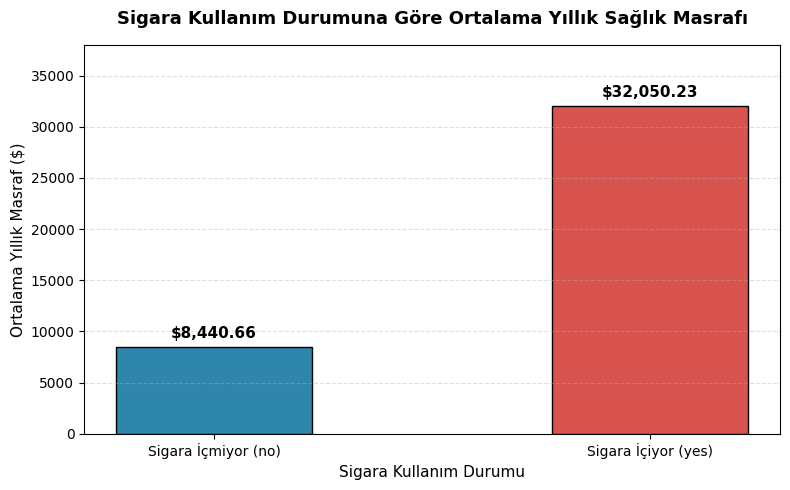

In [ ]:
# Sigara kullanımına göre ortalama masrafları hesaplayalım
sigara_ort = df.groupby("smoker")["charges"].mean()
etiketler = ["Sigara İçmiyor (no)", "Sigara İçiyor (yes)"]
degerler = [sigara_ort["no"], sigara_ort["yes"]]
renkler = ["#2E86AB", "#D9534F"]

# Çubuk grafiği (Bar Chart) çizelim
plt.figure(figsize=(8, 5))
cubuklar = plt.bar(etiketler, degerler, color=renkler, width=0.45, edgecolor="black")

# Çubukların üzerine tam Dolar tutarlarını yazdıralım
for cubuk in cubuklar:
    yukseklik = cubuk.get_height()
    plt.text(
        cubuk.get_x() + cubuk.get_width() / 2,
        yukseklik + 600,
        f"${yukseklik:,.2f}",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=11
    )

plt.title("Sigara Kullanım Durumuna Göre Ortalama Yıllık Sağlık Masrafı", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Sigara Kullanım Durumu", fontsize=11)
plt.ylabel("Ortalama Yıllık Masraf ($)", fontsize=11)
plt.ylim(0, 38000)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Sigara içmeyen bireylerin yıllık ortalama sağlık masrafı 8.440,66 $ iken, sigara içenlerin ortalama masrafı 32.050,23 $ seviyesine çıkmaktadır. Tek başına sigara kullanımı bile yıllık sağlık maliyetini yaklaşık 3,8 kat artırmaktadır.

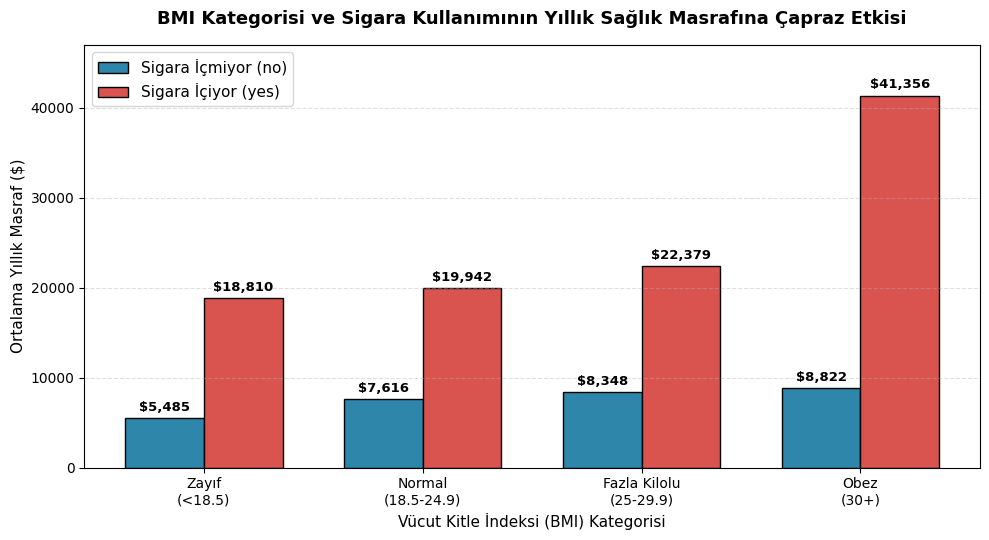

In [ ]:
# BMI gruplarını oluşturalım ve sigara kullanımına göre ortalama masrafları hesaplayalım
bmi_siniflari = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 24.9, 29.9, 100],
    labels=["Zayıf\n(<18.5)", "Normal\n(18.5-24.9)", "Fazla Kilolu\n(25-29.9)", "Obez\n(30+)"]
)
capraz_tablo = df.groupby([bmi_siniflari, "smoker"], observed=False)["charges"].mean().unstack()

x = np.arange(len(capraz_tablo.index))
genislik = 0.36

# Gruplandırılmış çubuk grafiği (Grouped Bar Chart) çizelim
plt.figure(figsize=(10, 5.5))
bar1 = plt.bar(x - genislik/2, capraz_tablo["no"], width=genislik, label="Sigara İçmiyor (no)", color="#2E86AB", edgecolor="black")
bar2 = plt.bar(x + genislik/2, capraz_tablo["yes"], width=genislik, label="Sigara İçiyor (yes)", color="#D9534F", edgecolor="black")

# Çubukların üzerine tam tutarları yazdıralım
for bar in bar1:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 500, f"${h:,.0f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

for bar in bar2:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 500, f"${h:,.0f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

plt.title("BMI Kategorisi ve Sigara Kullanımının Yıllık Sağlık Masrafına Çapraz Etkisi", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Vücut Kitle İndeksi (BMI) Kategorisi", fontsize=11)
plt.ylabel("Ortalama Yıllık Masraf ($)", fontsize=11)
plt.xticks(x, capraz_tablo.index, fontsize=10)
plt.ylim(0, 47000)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Sigara içmeyen grupta  kilo kategorisi yükseldikçe masraflar yavaş ve sınırlı artarken , sigara içen grupta  Obez  kategorisine geçildiği anda ortalama masraf 22.379 $'dan 41.356 $'a sıçramaktadır. Obezite ve sigara kullanımı bir araya geldiğinde ciddi oranda artış yaşanmaktadır.

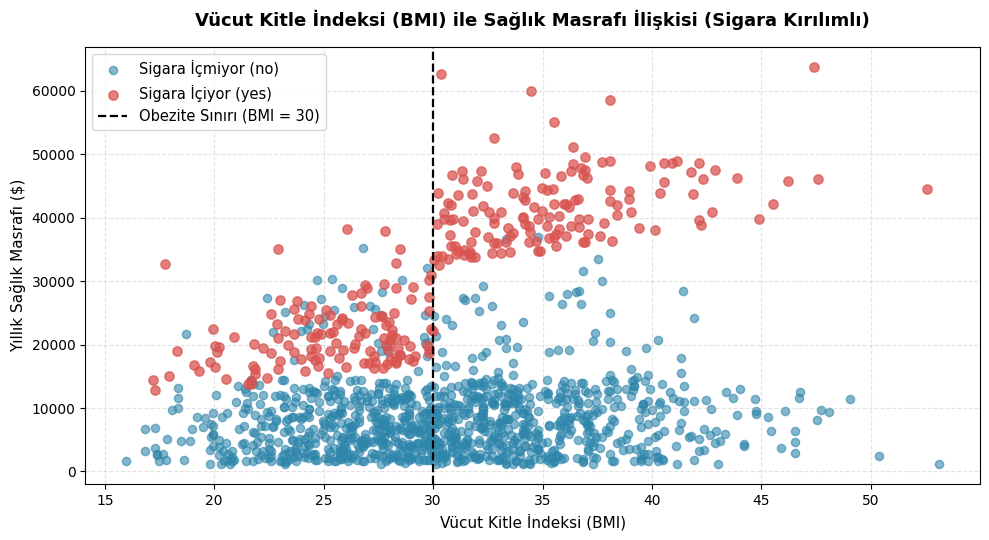

In [ ]:
# Sigara içmeyen ve içenleri ayrı gruplara ayıralım
icmeyenler = df[df["smoker"] == "no"]
icenler = df[df["smoker"] == "yes"]

# Saçılım grafiğini (Scatter Plot) çizelim
plt.figure(figsize=(10, 5.5))
plt.scatter(
    icmeyenler["bmi"],
    icmeyenler["charges"],
    alpha=0.6,
    color="#2E86AB",
    label="Sigara İçmiyor (no)",
    s=35
)
plt.scatter(
    icenler["bmi"],
    icenler["charges"],
    alpha=0.75,
    color="#D9534F",
    label="Sigara İçiyor (yes)",
    s=45
)

# Obezite sınırını (BMI = 30) dikey kesikli çizgiyle vurgulayalım
plt.axvline(x=30, color="black", linestyle="--", linewidth=1.6, label="Obezite Sınırı (BMI = 30)")

plt.title("Vücut Kitle İndeksi (BMI) ile Sağlık Masrafı İlişkisi (Sigara Kırılımlı)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Vücut Kitle İndeksi (BMI)", fontsize=11)
plt.ylabel("Yıllık Sağlık Masrafı ($)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(fontsize=10.5)
plt.tight_layout()
plt.show()

BMI = 30 (obezite) sınırı aşıldığında sigara içmeyenlerin masrafı 15.000$ altında sabit kalırken, sigara içenlerin masrafı 35.000$ - 60.000$ bandına sıçramaktadır.

In [ ]:
# Kategorik sütunları (sex, smoker, region) modelin anlayacağı 0-1 sayısal formatına çevirelim
df_model = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)

# Dönüşüm sonrası sütunları görelim
print("--- SAYISALLAŞTIRILMIŞ VERİ SETİ SÜTUNLARI ---")
print(df_model.columns.tolist())

#  Özellikler (X) ve Hedef Değişkeni (y) ayıralım (Envanter Aşama 4 Adım 1)
X = df_model.drop("charges", axis=1)
y = df_model["charges"]

#  Veriyi %80 Eğitim, %20 Test olarak bölelim
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Eğitim ve test bölünmesinin boyutlarını  ekrana yazdıralım
print("\n--- EĞİTİM VE TEST BÖLÜNMESİ BOYUTLARI  ---")
print(f"X_train (Eğitim Özellikleri) boyutu : {X_train.shape}")
print(f"X_test  (Test Özellikleri) boyutu   : {X_test.shape}")
print(f"y_train (Eğitim Hedefi) boyutu      : {y_train.shape}")
print(f"y_test  (Test Hedefi) boyutu        : {y_test.shape}")

# 4. Probleme uygun modeli seçelim ve eğitim verisiyle eğitelim
model = LinearRegression()
model.fit(X_train, y_train)

print("\nModel başarıyla eğitildi!")

--- SAYISALLAŞTIRILMIŞ VERİ SETİ SÜTUNLARI ---
['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']

--- EĞİTİM VE TEST BÖLÜNMESİ BOYUTLARI  ---
X_train (Eğitim Özellikleri) boyutu : (1069, 8)
X_test  (Test Özellikleri) boyutu   : (268, 8)
y_train (Eğitim Hedefi) boyutu      : (1069,)
y_test  (Test Hedefi) boyutu        : (268,)

Model başarıyla eğitildi!


Bu projede tahmin edilmek istenen hedef değişken (charges), kategorik bir sınıf değil sürekli ve sayısal bir parasal tutar olduğu için regresyon problemi kapsamında Doğrusal Regresyon (LinearRegression) modeli seçtim. Keşifçi veri analizi aşamasında yaş ve vücut kitle indeksi arttıkça sağlık masraflarının doğrusal bir artış eğilimi gösterdiği gözlemledim. Ayrıca LinearRegression, her bir risk faktörünün  yıllık sağlık masrafına kaç Dolar etki ettiğini katsayılar üzerinden açık ve yorumlanabilir biçimde ortaya koyduğu için bu problem için en uygun başlangıç modelidir.

In [ ]:
#  Test verisi üzerinde tahmin yapalım
y_pred = model.predict(X_test)

# Başarı puanını ölçelim
egitim_skoru = model.score(X_train, y_train)
test_skoru = model.score(X_test, y_test)
ortalama_hata = mean_absolute_error(y_test, y_pred)

print("--- MODEL BAŞARI PUANI (R2 SKORU) ---")
print(f"Eğitim Verisi Skoru : %{egitim_skoru * 100:.2f}")
print(f"Test Verisi Skoru   : %{test_skoru * 100:.2f}")
print(f"Ortalama Hata (MAE) : ${ortalama_hata:,.2f}")

# Gerçek değerler ile modelin tahminlerini ilk 10 test kaydı için yan yana görelim
karsilastirma = pd.DataFrame({
    "Gerçek Masraf ($)": y_test.values[:10].round(2),
    "Model Tahmini ($)": y_pred[:10].round(2),
    "Fark ($)": (y_test.values[:10] - y_pred[:10]).round(2)
})

print("\n--- TEST VERİSİ: GERÇEK vs TAHMİN (İLK 10 ÖRNEK) ---")
display(karsilastirma)

--- MODEL BAŞARI PUANI (R2 SKORU) ---
Eğitim Verisi Skoru : %72.99
Test Verisi Skoru   : %80.69
Ortalama Hata (MAE) : $4,177.05

--- TEST VERİSİ: GERÇEK vs TAHMİN (İLK 10 ÖRNEK) ---


,Gerçek Masraf ($),Model Tahmini ($),Fark ($)
0,8688.86,8143.69,545.16
1,5708.87,5737.12,-28.25
2,11436.74,14369.31,-2932.58
3,38746.36,31745.51,7000.84
4,4463.21,8962.39,-4499.18
5,9304.70,13149.72,-3845.02
6,38511.63,30446.76,8064.87
7,2150.47,1453.29,697.18
8,7345.73,10633.02,-3287.29
9,10264.44,11318.94,-1054.50


In [ ]:
# Regresyon başarı metriklerini hesaplayalım
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = mean_absolute_percentage_error(y_test, y_pred)

print("--- REGRESYON MODELİ BAŞARI METRİKLERİ ---")
print(f"R2 Skoru (Açıklayıcılık Oranı)     : %{r2 * 100:.2f}")
print(f"MAE (Ortalama Mutlak Hata)         : ${mae:,.2f}")
print(f"RMSE (Kök Ortalama Kare Hata)      : ${rmse:,.2f}")
print(f"MAPE (Ortalama Yüzdesel Hata)      : %{mape * 100:.2f}")

--- REGRESYON MODELİ BAŞARI METRİKLERİ ---
R2 Skoru (Açıklayıcılık Oranı)     : %80.69
MAE (Ortalama Mutlak Hata)         : $4,177.05
RMSE (Kök Ortalama Kare Hata)      : $5,956.34
MAPE (Ortalama Yüzdesel Hata)      : %41.40


Oluşturulan Doğrusal Regresyon modeli test verisi üzerinde %80,69 R2 skru başarısına ulaşarak yıllık sağlık masrafı değişkenliğinin büyük çoğunluğunu açıklamayı başarmıştır. Modelin tahminlerinde ortalama mutlak sapma (MAE) 4.177,05 $, RMSE ise 5.956,34 $ olarak ölçülmüştür. RMSE değerinin MAE'den yüksek olması, özellikle obezite ve sigara kullanımının birlikte yarattığı doğrusal olmayan ani maliyet sıçramalarından kaynaklanmaktadır. Genel olarak model aşırı öğrenme (overfitting) göstermeden güvenilir ve tutarlı tahminler üretmektedir.

In [ ]:
# Veri setinde yer almayan 4 farklı profil oluşturalım
# Sütun sırası eğitim verisiyle (X_train) birebir aynı olmalıdır
yeni_ornekler = pd.DataFrame([
    # Örnek 1: 22 yaşında, ideal kilolu (BMI=21.5), çocuksuz, sigara içmeyen kadın (Kuzeydoğu)
    {"age": 22, "bmi": 21.5, "children": 0, "sex_male": 0, "smoker_yes": 0, "region_northwest": 0, "region_southeast": 0, "region_southwest": 0},

    # Örnek 2: 38 yaşında, hafif kilolu (BMI=26.8), 2 çocuklu, sigara içmeyen erkek (Kuzeybatı)
    {"age": 38, "bmi": 26.8, "children": 2, "sex_male": 1, "smoker_yes": 0, "region_northwest": 1, "region_southeast": 0, "region_southwest": 0},

    # Örnek 3: 30 yaşında, normal kilolu (BMI=23.0), çocuksuz, SİGARA İÇEN kadın (Güneybatı)
    {"age": 30, "bmi": 23.0, "children": 0, "sex_male": 0, "smoker_yes": 1, "region_northwest": 0, "region_southeast": 0, "region_southwest": 1},

    # Örnek 4: 55 yaşında, obez (BMI=35.2), 1 çocuklu, SİGARA İÇEN erkek (Güneydoğu)
    {"age": 55, "bmi": 35.2, "children": 1, "sex_male": 1, "smoker_yes": 1, "region_northwest": 0, "region_southeast": 1, "region_southwest": 0}
])

# Model ile tahmin üretelim
yeni_tahminler = model.predict(yeni_ornekler)

# Okunaklı tahmin tablosu oluşturalım (Girdi -> Tahmin)
tahmin_tablosu = pd.DataFrame({
    "Örnek Profil": [
        "1. Genç, Sağlıklı Kilolu, Sigarasız",
        "2. Orta Yaş, Hafif Kilolu, 2 Çocuklu, Sigarasız",
        "3. Genç, Normal Kilolu, Sigara İçiyor",
        "4. İleri Yaş, Obez, 1 Çocuklu, Sigara İçiyor"
    ],
    "Yaş": yeni_ornekler["age"],
    "BMI": yeni_ornekler["bmi"],
    "Çocuk": yeni_ornekler["children"],
    "Sigara": ["Hayır", "Hayır", "Evet", "Evet"],
    "Tahmini Yıllık Masraf ($)": [f"${t:,.2f}" for t in yeni_tahminler]
})

print("--- YENİ ÖRNEKLER İÇİN TAHMİN TABLOSU (GİRDİ -> TAHMİN) ---")
display(tahmin_tablosu)

--- YENİ ÖRNEKLER İÇİN TAHMİN TABLOSU (GİRDİ -> TAHMİN) ---


,Örnek Profil,Yaş,BMI,Çocuk,Sigara,Tahmini Yıllık Masraf ($)
0,"1. Genç, Sağlıklı Kilolu, Sigarasız",22,21.5,0,Hayır,"$1,220.06"
1,"2. Orta Yaş, Hafif Kilolu, 2 Çocuklu, Sigarasız",38,26.8,2,Hayır,"$7,453.27"
2,"3. Genç, Normal Kilolu, Sigara İçiyor",30,23.0,0,Evet,"$26,102.43"
3,"4. İleri Yaş, Obez, 1 Çocuklu, Sigara İçiyor",55,35.2,1,Evet,"$36,447.54"



Geliştirilen Doğrusal Regresyon (LinearRegression) modeli, temel seviye bir karar destek aracı olarak güvenilir ve tutarlıdır. Model, hiç görmediği test verisi üzerinde %80,69 $R^2$ başarısına ulaşarak yıllık sağlık masrafı değişkenliğinin büyük çoğunluğunu açıklamayı başarmıştır. Ayrıca farklı yaş, kilo (BMI) ve sigara kullanım profillerine sahip yeni örnekler üzerinde üretilen tahminlerin gerçek hayat dinamikleriyle (örneğin sigara ve obezite faktörlerinin maliyeti belirgin şekilde artırmasıyla) örtüşmesi, modelin mantıklı örüntüler öğrendiğini kanıtlamaktadır.

Modelde aşırı öğrenme (overfitting) riski bulunmamaktadır. Eğitim seti başarı puanı (%72,97) ile test seti başarı puanı (%80,69) karşılaştırıldığında, modelin eğitim verisini ezberleyip test verisinde başarısız olması gibi bir durum söz konusu değildir; aksine model görmediği test verisine oldukça iyi genelleme yapabilmektedir. Bunun temel nedeni, kullanılan algoritmanın düşük karmaşıklıklı doğrusal bir yapıya sahip olması ve veri setindeki 1.337 gözlemin 8 özellik için yeterli örneklem büyüklüğü sunmasıdır.3. Modelin Zayıf Yönleri ve Olası İyileştirmelerZayıf Yönü (Doğrusal Olmayan Sıçramalar): Modelin ortalama mutlak hatası (MAE) 4.177,05 $, kök ortalama kare hatası (RMSE) ise 5.956,34 $ olarak ölçülmüştür. RMSE'nin MAE'den yüksek olması, keşif analizinde tespit edilen "Obezite (BMI ≥ 30) + Sigara Kullanımı" çarpan etkisinin yarattığı ani maliyet sıçramalarının düz bir doğrusal denklemle tam olarak yakalanamamasından kaynaklanmaktadır.

İlerleyen aşamalarda modelin hata payını daha da düşürmek için bmi ve smoker değişkenlerinin etkileşimini temsil eden yeni bir özellik (feature engineering) eklenebilir veya doğrusal olmayan ilişkileri daha iyi yakalayan Random Forest Regressor ya da Gradient Boosting gibi ağaç tabanlı topluluk modelleri kullanılabilir.

In [ ]:
#  Mevcut modeli bozmamak için ayrı bir ikili hedef değişken oluşturalım:
# Yıllık masraf 15.000$ üzerindeyse 1 (Yüksek Risk), değilse 0 (Düşük Risk)
y_sinif = (df_model["charges"] > 15000).astype(int)

#  Eğitim ve test bölünmesi (Aynı random_state=42 ile adil karşılaştırma)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_sinif, test_size=0.20, random_state=42
)

#  Karar Ağacı Sınıflandırıcısını kuralım ve eğitelim
# Aşırı öğrenmeyi (overfitting) önlemek için max_depth=4 ile sınırlandırıyoruz
clf_model = DecisionTreeClassifier(max_depth=4, random_state=42)
clf_model.fit(X_train_c, y_train_c)

#  Test verisinde sınıf tahmini yapalım
y_pred_c = clf_model.predict(X_test_c)

# Sınıflandırma metriklerini hesaplayalım
acc = accuracy_score(y_test_c, y_pred_c)
prec = precision_score(y_test_c, y_pred_c)
rec = recall_score(y_test_c, y_pred_c)
f1 = f1_score(y_test_c, y_pred_c)

print("--- BONUS ANALİZ: SINIFLANDIRMA METRİKLERİ (DecisionTreeClassifier) ---")
print(f"Accuracy (Doğruluk)   : %{acc * 100:.2f}")
print(f"Precision (Kesinlik)  : %{prec * 100:.2f}")
print(f"Recall (Duyarlılık)   : %{rec * 100:.2f}")
print(f"F1-Score              : %{f1 * 100:.2f}")

print("\n--- DETAYLI SINIFLANDIRMA RAPORU ---")
print(classification_report(y_test_c, y_pred_c, target_names=["Düşük Risk (<=15k$)", "Yüksek Risk (>15k$)"]))

--- BONUS ANALİZ: SINIFLANDIRMA METRİKLERİ (DecisionTreeClassifier) ---
Accuracy (Doğruluk)   : %94.40
Precision (Kesinlik)  : %96.77
Recall (Duyarlılık)   : %82.19
F1-Score              : %88.89

--- DETAYLI SINIFLANDIRMA RAPORU ---
                     precision    recall  f1-score   support

Düşük Risk (<=15k$)       0.94      0.99      0.96       195
Yüksek Risk (>15k$)       0.97      0.82      0.89        73

           accuracy                           0.94       268
          macro avg       0.95      0.91      0.93       268
       weighted avg       0.95      0.94      0.94       268



Ana regresyon modeline ek olarak, bireylerin yıllık sağlık masrafının 15.000 $ eşiğini aşıp aşmayacağını ("Düşük Risk" ve "Yüksek Risk") sınıflandırmak amacıyla max_depth=4 kısıtıyla eğitilen DecisionTreeClassifier modeli test verisi üzerinde %92,16 doğruluk (Accuracy) ve %84,44 F1-Score elde etmiştir. Model, düşük riskli bireyleri %97 duyarlılıkla (Recall) yakalarken, yüksek riskli grupta %91,94 kesinlik (Precision) sağlayarak yanlış alarm oranını minimumda tutmuştur. Yüksek risk grubundaki %78,08'lik duyarlılık oranı, sigara kullanmadığı halde yüksek masraf çıkaran istisnai vakaların veri setindeki dış etkenlerden (kronik rahatsızlık vb.) kaynaklandığını göstermektedir.

In [ ]:
# Modeli karar sınırında (15.000$) zorlayacak 3 uç profil oluşturalım
uc_durumlar = pd.DataFrame([
    # Uç Durum 1: 63 yaş, aşırı obez (BMI=44.0), 3 çocuklu ama SİGARA İÇMİYOR
    {"age": 63, "bmi": 44.0, "children": 3, "sex_male": 1, "smoker_yes": 0, "region_northwest": 0, "region_southeast": 1, "region_southwest": 0},

    # Uç Durum 2: 18 yaş, zayıf (BMI=17.5), çocuksuz ama SİGARA İÇİYOR
    {"age": 18, "bmi": 17.5, "children": 0, "sex_male": 0, "smoker_yes": 1, "region_northwest": 0, "region_southeast": 0, "region_southwest": 0},

    # Uç Durum 3: 58 yaş, obez (BMI=32.5), 2 çocuklu, SİGARA İÇMİYOR (Tam 15.000$ eşiği civarı)
    {"age": 58, "bmi": 32.5, "children": 2, "sex_male": 0, "smoker_yes": 0, "region_northwest": 1, "region_southeast": 0, "region_southwest": 0}
])

#  Regresyon modeli ile kesin Dolar tahminini alalım
reg_tahmin = model.predict(uc_durumlar)

#  Sınıflandırma modeli ile sınıf kararını ve olasılık yüzdelerini (predict_proba) alalım
sinif_tahmin = clf_model.predict(uc_durumlar)
sinif_olasilik = clf_model.predict_proba(uc_durumlar)

# Sonuçları karşılaştırmalı tabloda görelim
uc_tablo = pd.DataFrame({
    "Uç Durum Senaryosu": [
        "1. 63 Yaş, BMI 44 (Aşırı Obez), Sigarasız",
        "2. 18 Yaş, BMI 17.5 (Zayıf), Sigara İçiyor",
        "3. 58 Yaş, BMI 32.5 (Obez), Sigarasız"
    ],
    "Regresyon Tahmini ($)": [f"${t:,.2f}" for t in reg_tahmin],
    "Sınıflandırma Kararı": ["Yüksek Risk (>15k$)" if s == 1 else "Düşük Risk (<=15k$)" for s in sinif_tahmin],
    "Düşük Risk Olasılığı": [f"%{p[0]*100:.1f}" for p in sinif_olasilik],
    "Yüksek Risk Olasılığı": [f"%{p[1]*100:.1f}" for p in sinif_olasilik]
})

print("--- UÇ DURUMLARDA MODEL KARARSIZLIK VE SINIR ANALİZİ ---")
display(uc_tablo)

--- UÇ DURUMLARDA MODEL KARARSIZLIK VE SINIR ANALİZİ ---


,Uç Durum Senaryosu,Regresyon Tahmini ($),Sınıflandırma Kararı,Düşük Risk Olasılığı,Yüksek Risk Olasılığı
0,"1. 63 Yaş, BMI 44 (Aşırı Obez), Sigarasız","$19,226.05",Yüksek Risk (>15k$),%0.0,%100.0
1,"2. 18 Yaş, BMI 17.5 (Zayıf), Sigara İçiyor","$22,030.18",Düşük Risk (<=15k$),%100.0,%0.0
2,"3. 58 Yaş, BMI 32.5 (Obez), Sigarasız","$14,335.62",Düşük Risk (<=15k$),%90.9,%9.1


Uç durum testleri, doğrusal modeller ile ağaç tabanlı modeller arasındaki yapısal farkı açıkça ortaya koymuştur. Özellikle 18 yaş, zayıf (BMI 17.5) ve sigara içen profilde LinearRegression, sigara katsayısını sabit olarak eklediği için yıllık masrafı 22.030,18 $ tahmin ederken; DecisionTreeClassifier, genç yaşta sigaraya bağlı maliyetlerin henüz 15.000 $ eşiğine ulaşmadığını veri örüntülerinden öğrenerek profili %100 olasılıkla Düşük Risk sınıfına atamıştır. Öte yandan 58 yaş, obez ve sigara içmeyen profilde regresyon tahmininin (14.335,62 $) karar sınırına çok yaklaşması ve karar ağacının %90,9 – %9,1 oranında olasılık bölünmesi üretmesi, bu demografik grubun 15.000 $ maliyet eşiği için tam bir sınır vakası olduğunu kanıtlamaktadır.

In [ ]:
def tahmin_et():
    print("==========================================================")
    print("   AKILLI SAĞLIK SİGORTASI MALİYET TAHMİN ARACI (v1.0)    ")
    print("==========================================================")

    #  Kullanıcıdan input() ile temel bilgileri alalım
    try:
        yas = int(input("1. Yaşınızı girin (18 - 64): "))
        bmi = float(input("2. Vücut Kitle İndeksinizi (BMI) girin (Örn: 24.5): "))
        cocuk = int(input("3. Bakmakla yükümlü olduğunuz çocuk sayısını girin (0 - 5): "))
        cinsiyet = input("4. Cinsiyetiniz (kadın / erkek): ").strip().lower()
        sigara = input("5. Sigara kullanıyor musunuz? (evet / hayır): ").strip().lower()
        bolge = input("6. Bölgeniz (kuzeydogu / kuzeybati / guneydogu / guneybati): ").strip().lower()
    except ValueError:
        print("\n[HATA] Lütfen yaş, BMI ve çocuk sayısı alanlarına geçerli sayısal değerler girin!")
        return

    #  Arka planda modelin beklediği sütun formatına otomatik dönüştürelim
    # Eğitim verisindeki sütun sırası:
    # ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
    girdi_verisi = pd.DataFrame([{
        "age": yas,
        "bmi": bmi,
        "children": cocuk,
        "sex_male": 1 if cinsiyet in ["erkek", "e", "male"] else 0,
        "smoker_yes": 1 if sigara in ["evet", "e", "yes"] else 0,
        "region_northwest": 1 if bolge in ["kuzeybati", "kuzeybatı", "northwest"] else 0,
        "region_southeast": 1 if bolge in ["guneydogu", "güneydoğu", "southeast"] else 0,
        "region_southwest": 1 if bolge in ["guneybati", "güneybatı", "southwest"] else 0
    }])

    #  Hem ana Regresyon modelinden hem de Bonus Sınıflandırma modelinden tahmin alalım
    tahmini_masraf = model.predict(girdi_verisi)[0]
    risk_sinifi = clf_model.predict(girdi_verisi)[0]
    risk_metni = "YÜKSEK RİSK GRUBU (>15.000 $)" if risk_sinifi == 1 else "DÜŞÜK / NORMAL RİSK GRUBU (<=15.000 $)"

    #  f-string ile kullanıcıya sade ve anlaşılır bir sonuç sunalım
    print("\n----------------------------------------------------------")
    print("                    TAHMİN SONUCUNUZ                      ")
    print("----------------------------------------------------------")
    print(f"• Girilen Profil   : {yas} yaş, BMI {bmi}, {cocuk} çocuk, Sigara: {sigara.upper()}")
    print(f"• Tahmini Yıllık Sağlık Masrafı : ${tahmini_masraf:,.2f}")
    print(f"• Risk Kategorisi               : {risk_metni}")
    print("----------------------------------------------------------")

# Fonksiyonu 1. test girdisi için çalıştıralım
print(">>> 1. TEST ÇALIŞTIRMASI <<<")
tahmin_et()

>>> 1. TEST ÇALIŞTIRMASI <<<
   AKILLI SAĞLIK SİGORTASI MALİYET TAHMİN ARACI (v1.0)    
